# 12 · Comparison of All Models (CO5)

**Theory.** *Accuracy* = share of correct predictions. For one class: *precision* = of the documents we
labelled X, how many really are X; *recall* = of the real X documents, how many we found; *F1* =
their harmonic mean, 2PR/(P+R). *Macro* averaging computes each metric per class and takes the plain
mean, so all classes count equally; *micro* averaging pools all decisions (for single-label
classification, micro-F1 = accuracy). A difference between two models is only meaningful if it is
larger than the noise, so we add paired-bootstrap confidence intervals.

**Rule for this notebook:** every number comes from `results/*.json` (written by nb01–nb11). Nothing is
typed in by hand. This notebook also writes `docs/RESULTS.md` and the results table in `README.md`.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import src.utils  # FIRST: cache folders

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.utils import ROOT, SEED
from src.data import AG_LABELS, load
from src.evaluate import load_results, plot_confusion

pd.set_option("display.max_colwidth", 160)
R = load_results()
assert not any(r.get("fast_mode") for r in R.values()), "a FAST-mode result is in results/: re-run it"
FIG = ROOT / "report" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
print(sorted(R))

['bert_gpt_demos', 'bilstm', 'bow', 'distilbert', 'glove', 'ngram', 'pos_ner', 'preprocess', 'qa', 'semantic_search', 'summarization', 'tfidf', 'tweet_sentiment', 'word2vec']


## Table 1 · AG News classification (7,600 test documents)

In [2]:
names = {"bow": "BoW uni+bi + LR", "tfidf": "TF-IDF uni+bi + LR", "word2vec": "Word2Vec skip-gram avg + LR",
         "glove": "GloVe avg + LR", "bilstm": "BiLSTM (GloVe init)", "distilbert": "DistilBERT fine-tuned"}
t1 = pd.DataFrame([{
    "model": names[k], "accuracy": R[k]["metrics"]["accuracy"], "macro P": R[k]["metrics"]["macro_precision"],
    "macro R": R[k]["metrics"]["macro_recall"], "macro F1": R[k]["metrics"]["macro_f1"],
    "train time (s)": R[k]["train_time_s"], "inference (ms/doc)": R[k]["infer_ms_per_doc"],
    "size (MB)": R[k]["model_size_mb"]} for k in names]).set_index("model")
t1

,accuracy,macro P,macro R,macro F1,train time (s),inference (ms/doc),size (MB)
model,,,,,,,
BoW uni+bi + LR,0.8982,0.8979,0.8982,0.8979,2.08,0.568,5.42
TF-IDF uni+bi + LR,0.9018,0.9014,0.9018,0.9015,2.49,0.569,6.28
Word2Vec skip-gram avg + LR,0.8861,0.8859,0.8861,0.8860,24.33,0.134,11.10
GloVe avg + LR,0.8828,0.8826,0.8828,0.8827,0.29,0.135,160.00
BiLSTM (GloVe init),0.9066,0.9079,0.9066,0.9067,80.20,0.185,12.10
DistilBERT fine-tuned,0.9174,0.9173,0.9174,0.9173,1448.20,9.962,267.80


Notes on the columns:
- Train time includes embedding training for Word2Vec (GloVe's pre-training is not ours, so ~0).
  DistilBERT was fine-tuned on 20k rows on Apple MPS; the others trained on 30k rows on CPU.
- Inference is batched ms per document, including preprocessing, measured on a laptop that was
  short of memory. Treat it as order of magnitude: DistilBERT measured 44.6 and later 10.0 ms/doc
  in two runs of the same code (docs/research_notes.md §9).
- Size is the stored model. GloVe's 160 MB is the 400k-word vector table.

### Are the differences real? Paired bootstrap, 1,000 resamples of the test set

In [3]:
test = load("ag_test")
y = test.label.to_numpy()
pred = {k: np.array(R[k]["y_pred"]) for k in names}
best = t1["accuracy"].idxmax()
best_key = {v: k for k, v in names.items()}[best]
rng = np.random.default_rng(SEED)
idx = rng.integers(0, len(y), size=(1000, len(y)))
rows = []
for other in names:
    if other == best_key:
        continue
    a, b = pred[best_key] == y, pred[other] == y
    diffs = a[idx].mean(1) - b[idx].mean(1)
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    rows.append({"comparison": f"{best} − {names[other]}", "accuracy diff": round(a.mean() - b.mean(), 4),
                 "95% CI": f"[{lo:+.4f}, {hi:+.4f}]", "significant": bool(lo > 0 or hi < 0)})
boot = pd.DataFrame(rows)
boot

,comparison,accuracy diff,95% CI,significant
0,DistilBERT fine-tuned − BoW uni+bi + LR,0.0192,"[+0.0129, +0.0253]",True
1,DistilBERT fine-tuned − TF-IDF uni+bi + LR,0.0155,"[+0.0099, +0.0211]",True
2,DistilBERT fine-tuned − Word2Vec skip-gram avg + LR,0.0313,"[+0.0251, +0.0370]",True
3,DistilBERT fine-tuned − GloVe avg + LR,0.0346,"[+0.0284, +0.0407]",True
4,DistilBERT fine-tuned − BiLSTM (GloVe init),0.0108,"[+0.0055, +0.0162]",True


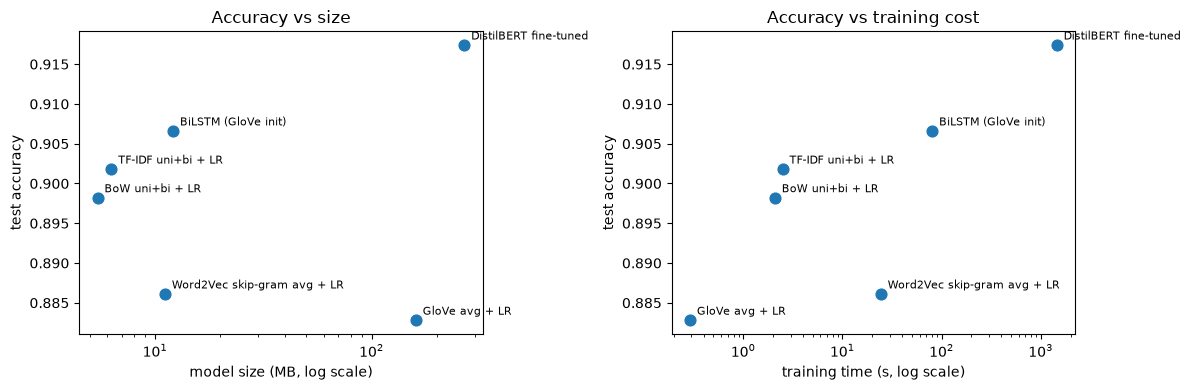

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, label in [(axes[0], "size (MB)", "model size (MB, log scale)"),
                       (axes[1], "train time (s)", "training time (s, log scale)")]:
    ax.scatter(t1[col], t1["accuracy"], s=60)
    for name, r in t1.iterrows():
        ax.annotate(name, (r[col], r["accuracy"]), textcoords="offset points", xytext=(5, 4), fontsize=8)
    ax.set_xscale("log"); ax.set_xlabel(label); ax.set_ylabel("test accuracy")
axes[0].set_title("Accuracy vs size"); axes[1].set_title("Accuracy vs training cost")
plt.tight_layout(); plt.savefig(FIG / "accuracy_vs_cost.png", dpi=130); plt.show()

## Confusion matrices: TF-IDF and the best model

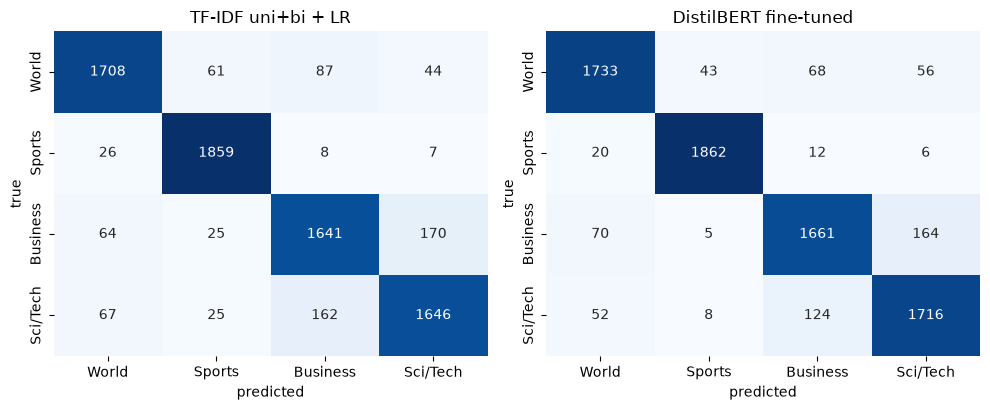

TF-IDF uni+bi + LR: 746 errors, 44.5% of them Business <-> Sci/Tech
DistilBERT fine-tuned: 628 errors, 45.9% of them Business <-> Sci/Tech


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
cms = {}
for ax, k in zip(axes, ["tfidf", best_key]):
    cms[k] = plot_confusion(y, pred[k], AG_LABELS, ax=ax, title=names[k])
plt.tight_layout(); plt.savefig(FIG / "confusion_tfidf_best.png", dpi=130); plt.show()

def biz_tech_share(cm):
    """Share of all errors that are Business <-> Sci/Tech confusions."""
    errors = cm.sum() - np.trace(cm)
    return (cm[2, 3] + cm[3, 2]) / errors

for k in cms:
    print(f"{names[k]}: {cms[k].sum() - np.trace(cms[k])} errors, "
          f"{biz_tech_share(cms[k]):.1%} of them Business <-> Sci/Tech")

## Error analysis: 10 documents the best model gets wrong

In [6]:
wrong = np.where(pred[best_key] != y)[0]
all_wrong = np.where(np.all([pred[k] != y for k in names], axis=0))[0]
print(f"{best} misclassifies {len(wrong)} documents; {len(all_wrong)} are wrong for ALL six models")
sample = np.random.default_rng(SEED).choice(wrong, size=10, replace=False)
err = pd.DataFrame({"text": test.text.to_numpy()[sample],
                    "true": [AG_LABELS[i] for i in y[sample]],
                    names[best_key]: [AG_LABELS[i] for i in pred[best_key][sample]],
                    names["tfidf"]: [AG_LABELS[i] for i in pred["tfidf"][sample]]})
err

DistilBERT fine-tuned misclassifies 628 documents; 313 are wrong for ALL six models


,text,true,DistilBERT fine-tuned,TF-IDF uni+bi + LR
0,"SAP Awarded $35 Million Postal Service Contract The postal service, which employs more than a third of the civilian employees of the federal government, cho...",Sci/Tech,Business,Business
1,"Ford underlines committed to motorsport. Despite confirming the successful sale of both Jaguar Racing and its Cosworth engine company to new owners, Ford Mo...",Sports,Business,Business
2,"Audit finds no fraud in Venezuelan recall vote CARACAS : An audit of last Sunday's recall vote in Venezuela, which favored keeping President Hugo Chavez in ...",Business,World,World
3,Henman Sails at the Swiss Indoors By Mark Ledsom BASEL (Reuters) - Britain's world number four Tim Henmanwon his opening match at the Swiss Indoors tennis t...,World,Sports,Sports
4,US football: Patriots' historic win New England win a record-tying 18th straight game - plus an NFL round-up.,World,Sports,Sports
5,"The C.E.O. Vanishes, and Other Mysteries Why did PeopleSoft, in the midst of a takeover fight with Oracle, fire its chief executive and president? Who knows...",Sci/Tech,Business,Business
6,"Contradiction in Terms : How to make beer It's been around for thousands of years. It has been worshiped, reviled, banned, and made the cornerstone of econo...",Sci/Tech,Business,Sci/Tech
7,"ASCAP Shakes Down Burning Man for Music Royalties LOS ANGELES, CA -- Officials from ASCAP today indicated they intend to pursue music royalties from the org...",Sci/Tech,World,World
8,Drug makers target counterfeits Big pharmaceutical companies are testing new tracking technology they hope will help them spot counterfeit drugs before they...,Business,Sci/Tech,Sci/Tech
9,Banks seek court ruling over F1 Three banks go to the High Court in London seeking a ruling which could lead to Bernie Ecclestone losing control of Formula ...,Business,Sports,Sports


What the ten rows show (sample drawn with seed 42):
- **Label noise is real.** "Henman Sails at the Swiss Indoors" (tennis) and "US football: Patriots'
  historic win" are labelled *World*. Both models say Sports, which is correct. AG labels come from the
  news source's section, not from an annotator reading the text.
- **Genuinely mixed topics:** "SAP awarded $35M Postal Service contract" (Sci/Tech label, Business
  prediction), "Banks seek court ruling over F1" (Business label, Sports prediction), "Drug makers target
  counterfeits" (Business vs Sci/Tech). Both labels are defensible.
- In 9 of the 10 rows TF-IDF makes the *same* mistake as DistilBERT: the remaining errors are mostly
  not about model power.
- About half of the best model's errors are shared by all six models (count above), and the five
  all-model errors below include "Oil prices bubble to record high" and "Stocks climb on drop in consumer
  prices" labelled *World*. **The ceiling on this test set is set partly by label noise**, which is also
  why the gap between a 6 MB TF-IDF model and a 268 MB transformer is only ~1.5 points.

In [7]:
print("Examples every model gets wrong:")
pd.DataFrame({"text": test.text.to_numpy()[all_wrong[:5]],
              "true": [AG_LABELS[i] for i in y[all_wrong[:5]]],
              "all models said": [AG_LABELS[i] for i in pred[best_key][all_wrong[:5]]]})

Examples every model gets wrong:


,text,true,all models said
0,"Rivals Try to Turn Tables on Charles Schwab By MICHAEL LIEDTKE SAN FRANCISCO (AP) -- With its low prices and iconoclastic attitude, discount stock broker Ch...",Sci/Tech,Business
1,"Intel to delay product aimed for high-definition TVs SAN FRANCISCO -- In the latest of a series of product delays, Intel Corp. has postponed the launch of a...",Business,Sci/Tech
2,Stocks Climb on Drop in Consumer Prices NEW YORK - Stocks rose for a second straight session Tuesday as a drop in consumer prices allowed investors to put a...,World,Business
3,Yahoo! Ups Ante for Small Businesses Web giant Yahoo! is gambling that price cuts on its domain name registration and Web hosting products will make it more...,Business,Sci/Tech
4,"Oil prices bubble to record high The price of oil has continued its sharp rise overnight, closing at a record high. The main contract in New York, light swe...",World,Business


## Table 2 · Summarization (100 BBC articles, ROUGE F1 vs extractive references)

In [8]:
t2 = pd.DataFrame(R["summarization"]["rouge"]).set_index("system")[
    ["rouge1 F1", "rouge2 F1", "rougeL F1", "rouge1 P", "rouge1 R", "summary words", "seconds/article"]]
print(f"reference sentences copied verbatim from the article: "
      f"{R['summarization']['reference_sentences_copied_pct']}%")
t2

reference sentences copied verbatim from the article: 96.1%


,rouge1 F1,rouge2 F1,rougeL F1,rouge1 P,rouge1 R,summary words,seconds/article
system,,,,,,,
Lead-3,0.4667,0.3839,0.3578,0.7786,0.3519,60.12,0.0001
TextRank,0.5907,0.5604,0.4607,0.9480,0.4542,65.82,0.0243
DistilBART,0.3709,0.2638,0.2796,0.7533,0.2566,49.13,2.9455


## Table 3 · Question answering (NewsBot on 2,089 BBC articles)

In [9]:
q = R["qa"]
t3 = pd.DataFrame([
    ("retrieval hit@1 (answerable questions)", q["retrieval_hit_at_1"]),
    ("retrieval hit@3", q["retrieval_hit_at_3"]),
    ("reader exact match, end to end", q["reader_em"]),
    ("reader F1, end to end", q["reader_f1"]),
    ("reader exact match given the gold passage", q["oracle_reader_em"]),
    ("reader F1 given the gold passage", q["oracle_reader_f1"]),
    ("answer-or-abstain accuracy at tuned threshold (40 questions)", q["answer_or_abstain_accuracy"]),
    ("confidence threshold", q["threshold"]),
], columns=["metric", "value"]).set_index("metric")
print(f"{q['n_answerable']} answerable + {q['n_unanswerable']} unanswerable questions, "
      f"{q['n_passages']:,} passages")
t3

30 answerable + 10 unanswerable questions, 9,937 passages


,value
metric,
retrieval hit@1 (answerable questions),0.8330
retrieval hit@3,0.9330
"reader exact match, end to end",0.7670
"reader F1, end to end",0.8020
reader exact match given the gold passage,0.9330
reader F1 given the gold passage,0.9520
answer-or-abstain accuracy at tuned threshold (40 questions),0.7500
confidence threshold,0.4806


## Table 4 · Tweet sentiment (TweetEval, 12,284 test tweets)

In [10]:
t4 = pd.DataFrame(R["tweet_sentiment"]["results"])
t4 = t4[t4.preprocessing.isin(["full", "raw text"])].set_index("model")[
    ["macro-recall", "macro-F1", "accuracy", "negative recall"]]
t4

,macro-recall,macro-F1,accuracy,negative recall
model,,,,
TF-IDF + LR,0.5743,0.5712,0.5969,0.3829
GloVe-Twitter avg + LR,0.6082,0.6046,0.6114,0.5637
"twitter-RoBERTa (reference, not fair)",0.7349,0.7240,0.7218,0.8066


## Table 5 · Other modules at a glance

In [11]:
ppl = {r["n"]: r["test PPL add-k=0.01"] for r in R["ngram"]["perplexity"]}
t5 = pd.DataFrame([
    ("nb01", "vocabulary: raw → cleaned (lemmatized)", f"{list(R['preprocess']['vocab_by_step'].values())[0]:,} → "
     f"{R['preprocess']['vocab_by_step']['+ lemmatize (WordNet+POS)']:,}"),
    ("nb02", "TF-IDF − BoW accuracy, unigrams (95% CI)",
     "{acc_diff:+.4f}, CI [{0:+.4f}, {1:+.4f}]".format(
         *R["tfidf"]["bootstrap_vs_other"]["TF-IDF unigram - BoW unigram"]["ci95"],
         acc_diff=R["tfidf"]["bootstrap_vs_other"]["TF-IDF unigram - BoW unigram"]["acc_diff"])),
    ("nb03", "test perplexity n=1 / 2 / 3 (add-k 0.01)", " / ".join(f"{ppl[n]:,.0f}" for n in (1, 2, 3))),
    ("nb04", "spaCy NER exact precision (30 hand-checked sentences)", R["pos_ner"]["ner_hand_check"]["precision_exact"]),
    ("nb04", "NLTK vs spaCy POS agreement (words)", f"{R['pos_ner']['nltk_spacy_pos_agreement']['fine_pct']}%"),
    ("nb08", "category precision@3, TF-IDF vs MiniLM",
     " vs ".join(str(v) for v in R["semantic_search"]["retrieval"]["category_precision_at_3"].values())),
    ("nb07", "BERT 'bank' cosine: same sense vs different sense",
     f"{R['bert_gpt_demos']['bank_bert_cosine']['money-2']['money-1']:.2f} vs "
     f"{R['bert_gpt_demos']['bank_bert_cosine']['river-1']['money-1']:.2f}"),
], columns=["notebook", "measure", "value"])
t5

,notebook,measure,value
0,nb01,vocabulary: raw → cleaned (lemmatized),"87,199 → 41,292"
1,nb02,"TF-IDF − BoW accuracy, unigrams (95% CI)","+0.0178, CI [+0.0130, +0.0228]"
2,nb03,test perplexity n=1 / 2 / 3 (add-k 0.01),"964 / 551 / 2,891"
3,nb04,spaCy NER exact precision (30 hand-checked sentences),0.671
4,nb04,NLTK vs spaCy POS agreement (words),94.3%
5,nb08,"category precision@3, TF-IDF vs MiniLM",0.907 vs 0.9379
6,nb07,BERT 'bank' cosine: same sense vs different sense,0.81 vs 0.48


## Write docs/RESULTS.md and the README results table

In [12]:
def md_table(df, index=True, floatfmt="{:.4g}"):
    """DataFrame -> Markdown table (no extra dependency)."""
    df = df.reset_index() if index else df
    fmt = lambda v: floatfmt.format(v) if isinstance(v, float) else str(v)
    lines = ["| " + " | ".join(map(str, df.columns)) + " |", "|" + "---|" * len(df.columns)]
    lines += ["| " + " | ".join(fmt(v) for v in row) + " |" for row in df.itertuples(index=False)]
    return "\n".join(lines)

results_md = f"""# NewsMind results

Generated by `notebooks/12_comparison.ipynb` from `results/*.json`. Do not edit by hand.

## Table 1 · AG News classification (7,600 test documents)
{md_table(t1)}

Latency was measured on a memory-constrained laptop and varies between runs; treat it as order of magnitude.

Paired bootstrap (1,000 resamples), best model vs each other model:
{md_table(boot, index=False)}

{names['tfidf']}: {biz_tech_share(cms['tfidf']):.1%} of errors are Business ↔ Sci/Tech;
{best}: {biz_tech_share(cms[best_key]):.1%}. {len(all_wrong)} test documents are misclassified by all six models.

## Table 2 · Summarization (100 BBC articles)
Reference sentences copied verbatim from the article: {R['summarization']['reference_sentences_copied_pct']}%.

{md_table(t2)}

## Table 3 · Question answering
{md_table(t3)}

## Table 4 · Tweet sentiment (TweetEval test, 12,284 tweets)
The twitter-RoBERTa row is a reference ceiling, not a fair comparison.

{md_table(t4)}

## Table 5 · Other modules
{md_table(t5, index=False)}
"""
(ROOT / "docs" / "RESULTS.md").write_text(results_md)

readme = (ROOT / "README.md").read_text()
block = ("<!-- RESULTS:START (generated by notebooks/12_comparison.ipynb) -->\n"
         + md_table(t1[["accuracy", "macro F1", "train time (s)", "inference (ms/doc)", "size (MB)"]])
         + "\n\nFull tables: [docs/RESULTS.md](docs/RESULTS.md)\n<!-- RESULTS:END -->")
readme = re.sub(r"<!-- RESULTS:START.*?<!-- RESULTS:END -->", block, readme, flags=re.S)
(ROOT / "README.md").write_text(readme)
print("wrote docs/RESULTS.md and updated README.md")

wrote docs/RESULTS.md and updated README.md


## Viva notes
**Q1. Macro vs micro F1?**
Macro-F1 averages the per-class F1 scores, so each class counts equally. Micro-F1 pools every decision
before computing F1; for single-label classification it equals accuracy. AG News is balanced, so they
are close here. On TweetEval (imbalanced, label shift) macro is the honest choice.

**Q2. Why does DistilBERT beat averaged Word2Vec, and by how much?**
See Table 1 and the bootstrap table. Contextual representations, word order via self-attention, and
pre-training on billions of words. Averaging static vectors discards order and dilutes keywords.

**Q3. Which model would you deploy, and why?**
TF-IDF + LR as the default: accuracy close to the best, a few MB, sub-millisecond inference, fully
explainable (top features). DistilBERT is opt-in when the extra accuracy is worth ~40× the size and
much higher latency. The API follows this choice.